# 03 · Uplift and offer policy: who should get which e-mail?

**Summary.** The production uplift model is reproduced exactly: every customer's score, the decile check (top decile +13.1 points
of visits observed vs 6.1 on average), the targeting curve ($14,274 at 30% targeting, $49,734 at 100%) and the policy
table with its intervals (Mens to everyone $770 per 1,000 customers, the purchase-history rule $776, the model's
next-best offer $777). The deeper finding is about where the heterogeneity is. **Only the Womens e-mail has a
persuadable group that can be predicted** (visit-uplift ranking z = 6.4, predicted uplifts the right size with slope
0.90): it lifts visits of womens buyers by 7.4 points and of mens-only buyers by 1.1. The Mens e-mail works for everyone
(about 7 points, 13.4 for customers who bought both lines), and the rest of its predicted spread is noise (z = 1.1). No
segment prefers the Womens e-mail by a clear margin, so personalising adds **$7 per 1,000 customers over "Mens to
everyone" (paired 95% CI -$148 to +$171)**. A LightGBM T-learner and a transformed-outcome learner rank no better. Spend
is too sparse to learn from (spend-trained rankings reach |z| of 2.1 at best), so visit is the right ranking target.
**Recommendation:** send everyone the Mens e-mail and keep a 10% no-e-mail hold-out. Use the uplift ranking only when
contacts are limited, where its top 10% returns 3.6x the spend of a random 10%. Do not spend a test on personalised vs
"Mens to everyone": at the observed edge it would need about 94 million customers per arm.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

In [2]:
import json, time
import lightgbm as lgb
from scipy import stats
from threadpoolctl import threadpool_limits
from sklearn.linear_model import LogisticRegression, Ridge
threadpool_limits(4)
T0 = time.perf_counter()
h = F.load_hillstrom()
X = F.uplift_design(h)
arm, visit, spend = h["Arm"].values, h["visit"].values, h["spend"].values
N = len(h)
COL = {"Control": PALETTE["grey"], "Mens offer": PALETTE["navy"], "Womens offer": PALETTE["purple"]}

## 1. The decision, and why the model ranks on visits

Every customer can get the Mens e-mail, the Womens e-mail or nothing. The average effects are known from notebook 01:
both e-mails raise spend, the Mens e-mail by more. An uplift model is only worth running if customers *differ* in how
they respond, and if those differences can be predicted well enough to change who gets what.

The outcome that pays is spend, but only 0.9% of customers buy. Before choosing a target, compare how well a ranking
learnt on each outcome holds up out of sample. Each learner below is a cross-fitted T-learner (one model per arm,
every customer scored by models that never saw them). It is judged by AUUC: the area between its cumulative uplift
curve and random targeting, per customer, with a 200-draw bootstrap interval. The z column is AUUC divided by its
bootstrap standard error, a unit-free signal-to-noise ratio that can be compared across outcomes.

In [3]:
logit = lambda: LogisticRegression(max_iter=3000, C=0.5)
learnt = {"visit": F.cross_fit_arm_models(X, visit, arm, logit),
          "conversion": F.cross_fit_arm_models(X, h["conversion"].values, arm, logit),
          "spend": F.cross_fit_arm_models(X, spend, arm, lambda: Ridge(alpha=1.0))}
rows = []
for t in F.TREATMENTS:
    m = np.isin(arm, [t, "Control"])
    scores = {f"{o}-trained": (p[t] - p["Control"])[m] for o, p in learnt.items()}
    for out in ("visit", "conversion", "spend"):
        y = h[out].values[m]
        draws = F.auuc_draws(y, arm[m] == t, scores, n=200, seed=SEED)
        for k, s in scores.items():
            a = F.auuc(F.uplift_curve(y, arm[m] == t, s))
            rows.append({"treatment": t, "ranking learnt on": k, "judged on": out, "auuc": a,
                         "ci_low": draws[k].quantile(0.025), "ci_high": draws[k].quantile(0.975), "z": a / draws[k].std()})
why = pd.DataFrame(rows)
why_own = why[why["ranking learnt on"].str.split("-").str[0] == why["judged on"]].set_index(["treatment", "judged on"])
why_own

ranking learnt on    auuc  ci_low  ci_high       z
treatment    judged on                                                      
Mens offer   visit            visit-trained  0.0011 -0.0009   0.0033  1.0669
             conversion  conversion-trained -0.0005 -0.0010   0.0001 -1.6115
             spend            spend-trained -0.0522 -0.1425   0.0505 -1.0547
Womens offer visit            visit-trained  0.0063  0.0044   0.0081  6.4302
             conversion  conversion-trained  0.0006  0.0001   0.0012  2.2939
             spend            spend-trained  0.0867  0.0173   0.1724  2.0524

For the Womens e-mail, the visit-trained ranking is 6.4 standard errors better than random targeting, and the
spend-trained ranking 2.1. For the Mens e-mail, no outcome gives a ranking that can be told apart from random (|z| at
most 1.6): its effect is close to uniform. Visit has 25 times more positive outcomes than conversion, and the
signal-to-noise ratios show it.

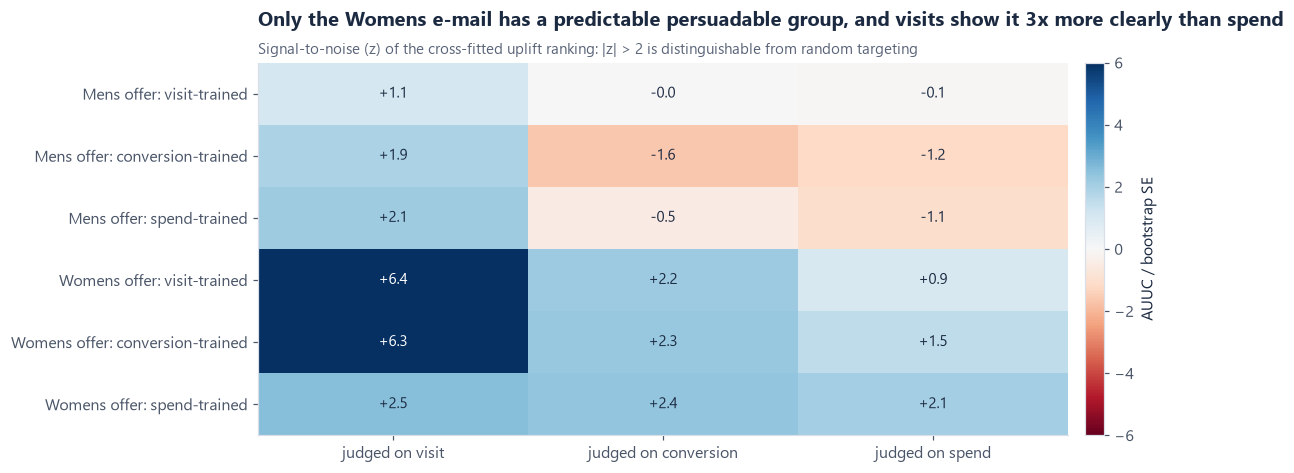

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.4))
tab = why.pivot_table(index=["treatment", "ranking learnt on"], columns="judged on", values="z").reindex(columns=["visit", "conversion", "spend"])
tab = tab.reindex([(t, f"{o}-trained") for t in F.TREATMENTS for o in ("visit", "conversion", "spend")])
im = ax.imshow(tab.values, cmap="RdBu", vmin=-6, vmax=6, aspect="auto")
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=10, color="white" if abs(v) > 4 else PALETTE["ink"])
ax.set_xticks(range(3), [f"judged on {c}" for c in tab.columns]); ax.set_yticks(range(len(tab)), [f"{a}: {b}" for a, b in tab.index])
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="AUUC / bootstrap SE")
headline(ax, "Only the Womens e-mail has a predictable persuadable group, and visits show it 3x more clearly than spend",
         "Signal-to-noise (z) of the cross-fitted uplift ranking: |z| > 2 is distinguishable from random targeting")
plt.show()

Read along a row: whatever a ranking was trained on, it is easiest to verify on visits. Visit is the outcome on which
differences in uplift are measurable at this sample size. That is why the ETL ranks on visit and values policies on spend,
where randomisation makes the policy-level estimate unbiased even though individual spend uplift cannot be learnt.

## 2. Reproduce the production uplift model

The ETL fits a cross-fitted logistic T-learner on visits (5 folds, seed 7, C = 0.5). Each customer's predicted uplift
for each e-mail is P(visit | e-mail) - P(visit | no e-mail). The model's offer is the e-mail with the larger uplift.
These are the scores behind the Power BI uplift pages. Reproduce them, the decile check and the targeting curve.

In [5]:
pub_rows = pd.read_csv(ROOT / "data" / "fact_email_test.csv", usecols=["UpliftMens", "UpliftWomens"])
pub_dec = pd.read_csv(ROOT / "data" / "uplift_decile_check.csv")
pub_curve = pd.read_csv(ROOT / "data" / "uplift_targeting_curve.csv")
pub = json.load(open(ROOT / "ml" / "metrics.json"))
P = learnt["visit"]
h["UpliftMens"], h["UpliftWomens"] = P["Mens offer"] - P["Control"], P["Womens offer"] - P["Control"]
h["BestUplift"] = h[["UpliftMens", "UpliftWomens"]].max(axis=1)
h["ModelOffer"] = np.where(h["UpliftMens"] >= h["UpliftWomens"], "Mens offer", "Womens offer")
h["UpliftDecile"] = 10 - pd.qcut(h["BestUplift"].rank(method="first"), 10, labels=False)
max_dev = max((h["UpliftMens"].round(4) - pub_rows["UpliftMens"]).abs().max(), (h["UpliftWomens"].round(4) - pub_rows["UpliftWomens"]).abs().max())


def decile_check(g):
    t_, c_ = g[g["Arm"].values == g["ModelOffer"].values], g[g["Arm"] == "Control"]
    d = t_["visit"].mean() - c_["visit"].mean()
    se = np.sqrt(t_["visit"].var() / len(t_) + c_["visit"].var() / len(c_))
    return pd.Series({"customers": len(g), "predicted": g["BestUplift"].mean(), "observed": d, "ci_low": d - 1.96 * se, "ci_high": d + 1.96 * se,
                      "observed_spend_uplift": t_["spend"].mean() - c_["spend"].mean(), "share_mens_offer": (g["ModelOffer"] == "Mens offer").mean()})


dchk = h.groupby("UpliftDecile").apply(decile_check, include_groups=False)
avg_pp = (h.loc[h["Arm"] != "Control", "visit"].mean() - h.loc[h["Arm"] == "Control", "visit"].mean()) * 100
SH = np.round(np.arange(0, 1.0001, 0.05), 2)
curve_rev = F.targeting_curve(h["BestUplift"], h["ModelOffer"], arm, spend, SH)
parity = pd.DataFrame({
    "published": {"max |uplift score difference|": 0.0, "top-decile observed visit uplift, pp": pub["uplift_top_decile_visit_pp"],
                  "average visit uplift, pp": pub["uplift_avg_visit_pp"], "incremental revenue at 30% targeting, $": pub["uplift_inc_at_30pct"],
                  "incremental revenue at 100% targeting, $": pub["uplift_inc_at_100pct"]},
    "reproduced": {"max |uplift score difference|": max_dev, "top-decile observed visit uplift, pp": dchk.loc[1, "observed"] * 100,
                   "average visit uplift, pp": avg_pp, "incremental revenue at 30% targeting, $": curve_rev[6], "incremental revenue at 100% targeting, $": curve_rev[-1]}})
assert max_dev < 1e-4
assert abs(dchk.loc[1, "observed"] * 100 - pub["uplift_top_decile_visit_pp"]) < 0.05 and abs(avg_pp - pub["uplift_avg_visit_pp"]) < 0.05
assert np.allclose(curve_rev, pub_curve["ModelIncRevenue"].values, rtol=0, atol=0.5)   # the ETL writes 6 significant digits
assert np.allclose(dchk["observed"].values, pub_dec["ObservedVisitUplift"].values, atol=1e-4)
parity

,published,reproduced
max |uplift score difference|,0.0000,0.0000
"top-decile observed visit uplift, pp",13.1000,13.1375
"average visit uplift, pp",6.1000,6.0882
"incremental revenue at 30% targeting, $","14,274.0400","14,274.0438"
"incremental revenue at 100% targeting, $","49,734.3400","49,734.3442"


Every score, the decile check and the whole targeting curve match the published files, to rounding.

## 3. Alternative learners on the same cross-fitted folds

Two alternatives to the production logistic T-learner, fitted on the same folds:

* **LightGBM T-learner**: the same structure with gradient-boosted arm models, which can find non-linear segments.
* **Transformed outcome**: one LightGBM regression per e-mail on Z = 2 x visit x (+1 e-mailed / -1 control), whose
  expectation *is* the uplift. It models the difference directly instead of two levels.

Each is judged per e-mail on its own randomised comparison (that arm vs control): the uplift curve, AUUC with a
bootstrap interval, the paired AUUC difference vs the production model, and the share of all incremental visits
captured by the top 30%.

In [6]:
gbm = lambda: lgb.LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8, subsample_freq=1,
                                 colsample_bytree=0.8, verbose=-1, n_jobs=4, random_state=SEED)
gbm_reg = lambda: lgb.LGBMRegressor(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=400, subsample=0.8, subsample_freq=1,
                                    colsample_bytree=0.8, verbose=-1, n_jobs=4, random_state=SEED)
P_gbm = F.cross_fit_arm_models(X, visit, arm, gbm)
U = {"Logistic T-learner (production)": {t: P[t] - P["Control"] for t in F.TREATMENTS},
     "LightGBM T-learner": {t: P_gbm[t] - P_gbm["Control"] for t in F.TREATMENTS},
     "Transformed outcome (LightGBM)": {t: F.cross_fit_transformed_outcome(X, visit, arm, t, gbm_reg) for t in F.TREATMENTS}}
learners = []
curves = {}
for t in F.TREATMENTS:
    m = np.isin(arm, [t, "Control"])
    sc = {k: v[t][m] for k, v in U.items()}
    sc["Random"] = np.random.default_rng(SEED).random(m.sum())
    draws = F.auuc_draws(visit[m], arm[m] == t, sc, n=200, seed=SEED)
    for k, s in sc.items():
        c = F.uplift_curve(visit[m], arm[m] == t, s)
        curves[(t, k)] = c
        d = draws[k] - draws["Logistic T-learner (production)"]
        learners.append({"treatment": t, "learner": k, "auuc": F.auuc(c), "ci_low": draws[k].quantile(0.025), "ci_high": draws[k].quantile(0.975),
                         "vs_production": d.mean(), "vs_production_ci": f"{d.quantile(0.025):+.4f} to {d.quantile(0.975):+.4f}",
                         "capture_top30": F.capture_at(c, 0.3)})
learners = pd.DataFrame(learners).set_index(["treatment", "learner"])
learners

auuc  ci_low  ci_high  vs_production    vs_production_ci  capture_top30
treatment    learner                                                                                                   
Mens offer   Logistic T-learner (production)  0.0011 -0.0009   0.0033         0.0000  +0.0000 to +0.0000         0.3335
             LightGBM T-learner               0.0008 -0.0014   0.0027        -0.0005  -0.0025 to +0.0016         0.3372
             Transformed outcome (LightGBM)   0.0006 -0.0013   0.0023        -0.0006  -0.0028 to +0.0017         0.3030
             Random                           0.0002 -0.0017   0.0019        -0.0010  -0.0037 to +0.0017         0.2977
Womens offer Logistic T-learner (production)  0.0063  0.0044   0.0081         0.0000  +0.0000 to +0.0000         0.3998
             LightGBM T-learner               0.0061  0.0038   0.0076        -0.0003  -0.0018 to +0.0013         0.4789
             Transformed outcome (LightGBM)   0.0057  0.0036   0.0070        -0.0008  -0.0022 to +0.0007         0.4463
             Random                          -0.0001 -0.0020   0.0017        -0.0063  -0.0085 to -0.0038         0.2717

No alternative learner beats the production logistic T-learner: the paired AUUC differences (-0.0003 to -0.0008) all have
intervals spanning zero. On the Mens e-mail, every learner's AUUC interval includes zero. On the Womens e-mail, all three
find the same group. The LightGBM T-learner gets more of the extra visits into its top 30% (48% vs 40%) but loses ground
further down. With no evidence of a better ranking, the simpler production model stays.

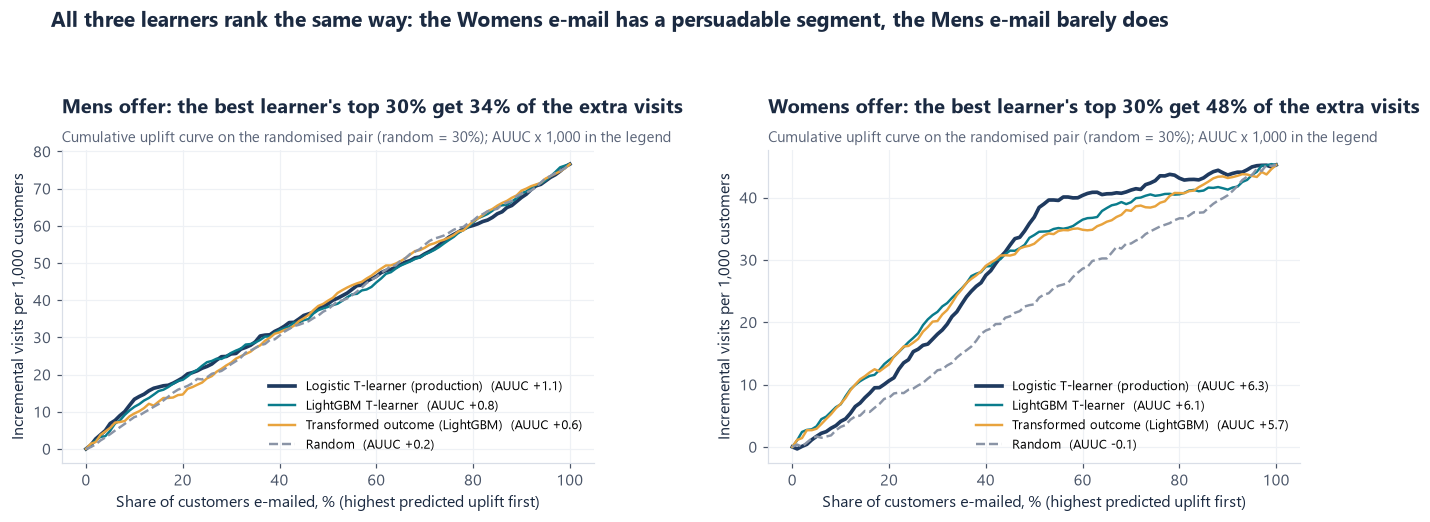

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
styles = {"Logistic T-learner (production)": (PALETTE["navy"], "-"), "LightGBM T-learner": (PALETTE["teal"], "-"),
          "Transformed outcome (LightGBM)": (PALETTE["amber"], "-"), "Random": (PALETTE["grey"], "--")}
for ax, t in zip(axes, F.TREATMENTS):
    n_pair = np.isin(arm, [t, "Control"]).sum()
    for k, (c_, ls) in styles.items():
        cv = curves[(t, k)]
        ax.plot(cv["share"] * 100, cv["incremental"] / n_pair * 1000, color=c_, ls=ls, lw=2.4 if "production" in k else 1.6,
                label=f"{k}  (AUUC {learners.loc[(t, k), 'auuc'] * 1000:+.1f})")
    ax.set_xlabel("Share of customers e-mailed, % (highest predicted uplift first)")
    ax.set_ylabel("Incremental visits per 1,000 customers")
    ax.legend(loc="lower right", fontsize=8.5)
    best = learners.loc[t]["capture_top30"].drop("Random").max()
    headline(ax, f"{t}: the best learner's top 30% get {best:.0%} of the extra visits",
             "Cumulative uplift curve on the randomised pair (random = 30%); AUUC x 1,000 in the legend")
fig.suptitle("All three learners rank the same way: the Womens e-mail has a persuadable segment, the Mens e-mail barely does",
             x=0.04, ha="left", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=(0, 0, 1, 0.92))
savefig(fig, "03-uplift-curves", FIG); plt.show()

## 4. Are the predicted uplifts the right size?

Ranking is not enough for a policy that weighs one e-mail against another: the uplift *values* should match what
happens. Per e-mail, sort customers into deciles of predicted uplift and compare the mean prediction with the observed
uplift (e-mailed minus control visit rate in that decile, 95% interval).

Weighted slope of observed on predicted uplift (1 = right size): {'Mens offer': np.float64(0.35), 'Womens offer': np.float64(0.9)}
Top decile of predicted Mens uplift: 100% bought both lines last year (base: 10%)


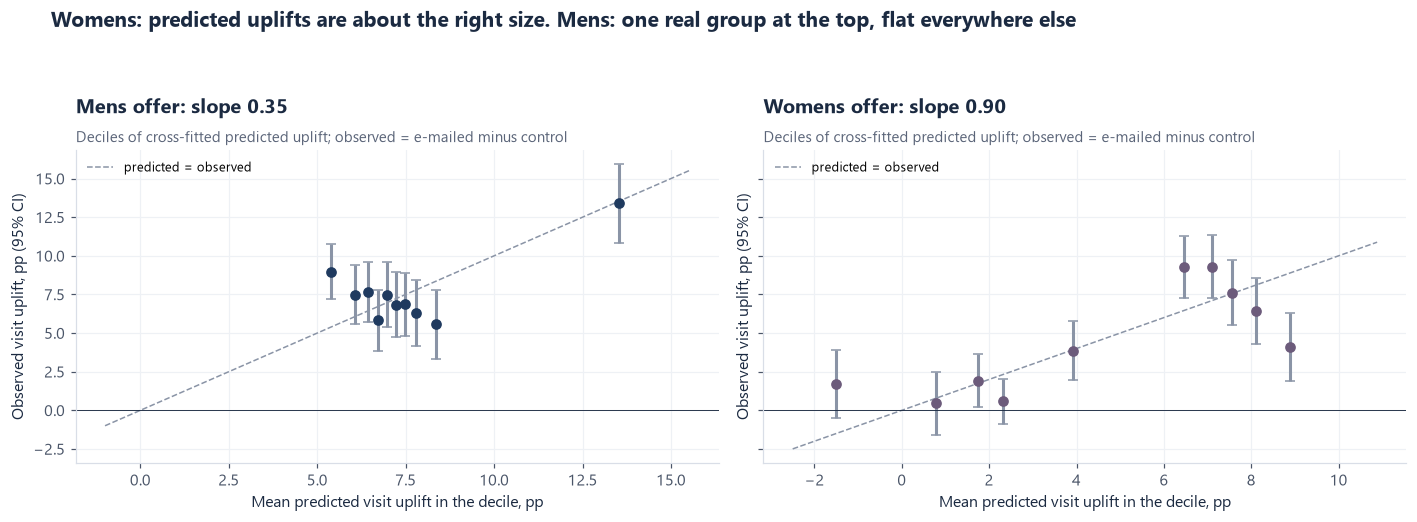

predicted                observed             
treatment Mens offer Womens offer Mens offer Womens offer
decile                                                   
1             0.1352       0.0888     0.1339       0.0409
2             0.0837       0.0810     0.0556       0.0643
3             0.0780       0.0756     0.0628       0.0762
4             0.0747       0.0710     0.0685       0.0931
5             0.0721       0.0647     0.0683       0.0929
6             0.0697       0.0393     0.0748       0.0387
7             0.0671       0.0233     0.0584       0.0058
8             0.0643       0.0175     0.0767       0.0192
9             0.0608       0.0079     0.0749       0.0045
10            0.0540      -0.0150     0.0898       0.0168

In [8]:
cal_rows = []
for t, col in zip(F.TREATMENTS, ("UpliftMens", "UpliftWomens")):
    d = 10 - pd.qcut(h[col].rank(method="first"), 10, labels=False)
    for k in range(1, 11):
        g = h[d == k]
        a, c = g.loc[g["Arm"] == t, "visit"], g.loc[g["Arm"] == "Control", "visit"]
        o = a.mean() - c.mean()
        se = np.sqrt(a.var() / len(a) + c.var() / len(c))
        cal_rows.append({"treatment": t, "decile": k, "predicted": g[col].mean(), "observed": o, "ci_low": o - 1.96 * se, "ci_high": o + 1.96 * se})
ucal = pd.DataFrame(cal_rows)
fit = {t: np.polyfit(g["predicted"], g["observed"], 1, w=1 / ((g["ci_high"] - g["ci_low"]) / 3.92) ** 2) for t, g in ucal.groupby("treatment")}
print("Weighted slope of observed on predicted uplift (1 = right size):", {t: round(v[0], 2) for t, v in fit.items()})
top_mens = h[(10 - pd.qcut(h["UpliftMens"].rank(method="first"), 10, labels=False)) == 1]
print(f"Top decile of predicted Mens uplift: {(top_mens['Purchased'] == 'Both').mean():.0%} bought both lines last year (base: {(h['Purchased'] == 'Both').mean():.0%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (t, g) in zip(axes, ucal.groupby("treatment")):
    ax.errorbar(g["predicted"] * 100, g["observed"] * 100, yerr=[(g["observed"] - g["ci_low"]) * 100, (g["ci_high"] - g["observed"]) * 100],
                fmt="o", color=COL[t], ecolor=PALETTE["grey"], capsize=3)
    lim = [min(-1, g["predicted"].min() * 100 - 1), g["predicted"].max() * 100 + 2]
    ax.plot(lim, lim, ls="--", color=PALETTE["grey"], lw=1, label="predicted = observed")
    ax.axhline(0, color=PALETTE["ink"], lw=0.6)
    ax.set_xlabel("Mean predicted visit uplift in the decile, pp"); ax.set_ylabel("Observed visit uplift, pp (95% CI)")
    ax.legend(loc="upper left", fontsize=8.5)
    headline(ax, f"{t}: slope {fit[t][0]:.2f}", "Deciles of cross-fitted predicted uplift; observed = e-mailed minus control")
fig.suptitle("Womens: predicted uplifts are about the right size. Mens: one real group at the top, flat everywhere else",
             x=0.04, ha="left", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
ucal.pivot(index="decile", columns="treatment", values=["predicted", "observed"])

Womens: the deciles track the diagonal (slope 0.90), except at the extremes. The top decile is predicted at 8.9 points and
observed at 4.1, the usual over-shoot of a T-learner, whose uplift is the difference of two noisy predictions. Mens: the
top decile is real (predicted 13.5, observed 13.4), and those are mostly customers who bought both lines last year. The
other nine deciles sit flat at about 7 points whatever the prediction, so the model's spread below the top is noise.

## 5. Policy evaluation: what is each assignment rule worth?

A policy assigns one arm to every customer. Because the arms were randomised with known probability 1/3, a policy's
value can be estimated without a model: the mean spend of the customers whose random arm *matches* what the policy
would have sent (self-normalised inverse-propensity weighting, the Hajek estimator). Intervals come from the ETL's
400-draw bootstrap, replayed with its random-number sequence so the published table is reproduced.

In [9]:
seg_rule = h.groupby("Purchased").apply(lambda g: pd.Series({a: g.loc[g["Arm"] == a, "spend"].mean() for a in F.ARMS}), include_groups=False)
seg_best = seg_rule[F.TREATMENTS].idxmax(axis=1)
policies = {"No e-mail": np.array(["Control"] * N), "All: Womens offer": np.array(["Womens offer"] * N), "All: Mens offer": np.array(["Mens offer"] * N),
            "Rule: by purchase history": h["Purchased"].map(seg_best).values, "Model: next-best offer": h["ModelOffer"].values}
base_spend = spend[arm == "Control"].mean()
rng = np.random.default_rng(42)                              # the ETL's generator, consumed in the same order
pol = []
for name, a in policies.items():
    v = F.policy_value(arm, a, spend)
    lo, hi = (0.0, 0.0) if name == "No e-mail" else np.percentile(F.policy_bootstrap(arm, a, spend, rng, 400), [2.5, 97.5])
    pol.append({"policy": name, "spend_per_customer": v, "inc_per_1000": (v - base_spend) * 1000, "ci_low_per_1000": lo * 1000, "ci_high_per_1000": hi * 1000,
                "visit_rate": F.policy_value(arm, a, visit), "share_mens": (a == "Mens offer").mean(), "share_womens": (a == "Womens offer").mean()})
pol = pd.DataFrame(pol).set_index("policy")
pub_pol = pd.read_csv(ROOT / "data" / "uplift_policies.csv").set_index("Policy")
assert np.allclose(pol["inc_per_1000"], pub_pol["IncPer1000"], atol=0.1) and np.allclose(pol["ci_low_per_1000"], pub_pol["CILowPer1000"], atol=0.1)
assert np.allclose(pol["ci_high_per_1000"], pub_pol["CIHighPer1000"], atol=0.1)
print("Rule by purchase history:", dict(seg_best))
pol

Rule by purchase history: {'Both': 'Mens offer', 'Mens only': 'Mens offer', 'Womens only': 'Womens offer'}


,spend_per_customer,inc_per_1000,ci_low_per_1000,ci_high_per_1000,visit_rate,share_mens,share_womens
policy,,,,,,,
No e-mail,0.6528,0.0000,0.0000,0.0000,0.1062,0.0000,0.0000
All: Womens offer,1.0772,424.4122,159.6714,677.3785,0.1514,0.0000,1.0000
All: Mens offer,1.4226,769.8272,487.7197,"1,023.9935",0.1828,1.0000,0.0000
Rule: by purchase history,1.4286,775.8387,489.9421,"1,050.7525",0.1842,0.5510,0.4490
Model: next-best offer,1.4299,777.0991,505.7874,"1,053.5245",0.1824,0.6967,0.3033


The published policy table is reproduced to the cent: Mens offer to everyone $769.8 per 1,000 customers, the purchase-
history rule $775.8 and the model's next-best offer $777.1. The intervals overlap almost completely. The question that
matters is paired: on the *same* bootstrap samples, how much does the model add over "send everyone the Mens offer"?

In [10]:
def paired_policy_diff(a, b, y, n=2000, seed=SEED):
    """Bootstrap of value(a) - value(b) on the same resamples."""
    r = np.random.default_rng(seed)
    out = np.empty(n)
    ma, mb = arm == a, arm == b
    for i in range(n):
        ix = r.integers(0, N, N)
        out[i] = (y[ix] * ma[ix]).sum() / ma[ix].sum() - (y[ix] * mb[ix]).sum() / mb[ix].sum()
    return out


h["ModelOfferGBM"] = np.where(U["LightGBM T-learner"]["Mens offer"] >= U["LightGBM T-learner"]["Womens offer"], "Mens offer", "Womens offer")
comparisons = {"Model (production) vs All Mens": h["ModelOffer"].values, "Rule vs All Mens": policies["Rule: by purchase history"],
               "Model (LightGBM) vs All Mens": h["ModelOfferGBM"].values}
pairs = []
for name, a in comparisons.items():
    for out, y in (("spend $ per 1,000", spend), ("visits per 1,000", visit)):
        d = paired_policy_diff(a, policies["All: Mens offer"], y) * 1000
        pairs.append({"comparison": name, "outcome": out, "difference": (F.policy_value(arm, a, y) - F.policy_value(arm, policies["All: Mens offer"], y)) * 1000,
                      "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5), "share_where_policies_differ": (a != "Mens offer").mean()})
pairs = pd.DataFrame(pairs).set_index(["comparison", "outcome"])
pairs

difference    ci_low  ci_high  share_where_policies_differ
comparison                     outcome                                                                      
Model (production) vs All Mens spend $ per 1,000      7.2720 -147.6770 170.8664                       0.3033
                               visits per 1,000      -0.3934   -4.1508   3.3470                       0.3033
Rule vs All Mens               spend $ per 1,000      6.0116 -181.1006 181.2996                       0.4490
                               visits per 1,000       1.4758   -3.1099   6.3677                       0.4490
Model (LightGBM) vs All Mens   spend $ per 1,000    111.0626  -12.8976 241.5943                       0.2732
                               visits per 1,000      -1.7777   -5.4173   1.9503                       0.2732

On the same bootstrap samples, the model's policy beats "Mens to everyone" by $7 per 1,000 customers (95% CI -$148 to
+$171) and loses 0.4 visits per 1,000 (CI -4.2 to +3.3). The purchase-history rule (Womens e-mail to womens-only buyers)
does the same: +$6. The two policies differ for 30% of customers, and for those customers the two e-mails do about equally
well. The LightGBM policy looks better on spend (+$111, CI -$13 to +$242) but produces fewer visits (-1.8 per 1,000). Two
outcomes that disagree, from the third learner tried, are not evidence of a better policy; at most it is a candidate.

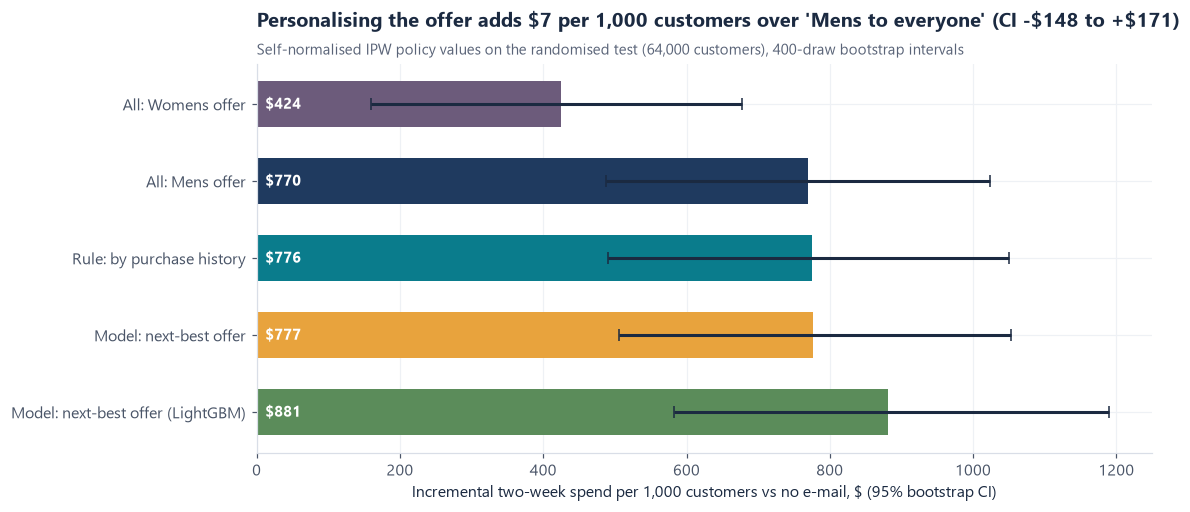

In [11]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
show = pol.drop("No e-mail").copy()
lo_g, hi_g = np.percentile(F.policy_bootstrap(arm, h["ModelOfferGBM"].values, spend, np.random.default_rng(SEED), 400), [2.5, 97.5]) * 1000
show.loc["Model: next-best offer (LightGBM)"] = {"inc_per_1000": (F.policy_value(arm, h["ModelOfferGBM"].values, spend) - base_spend) * 1000,
                                                 "ci_low_per_1000": lo_g, "ci_high_per_1000": hi_g}
yy = np.arange(len(show))
cols = [PALETTE["purple"], PALETTE["navy"], PALETTE["teal"], PALETTE["amber"], PALETTE["sage"]]
ax.barh(yy, show["inc_per_1000"], color=cols[: len(show)], height=0.6)
ok = show["ci_low_per_1000"].notna()
ax.errorbar(show.loc[ok, "inc_per_1000"], yy[ok.values], xerr=[show.loc[ok, "inc_per_1000"] - show.loc[ok, "ci_low_per_1000"],
            show.loc[ok, "ci_high_per_1000"] - show.loc[ok, "inc_per_1000"]], fmt="none", ecolor=PALETTE["ink"], capsize=4)
for i, v in enumerate(show["inc_per_1000"]):
    ax.text(12, i, f"${v:,.0f}", va="center", color="white", fontweight="bold", fontsize=10)
ax.set_yticks(yy, show.index); ax.invert_yaxis()
ax.set_xlabel("Incremental two-week spend per 1,000 customers vs no e-mail, $ (95% bootstrap CI)")
md = pairs.loc[("Model (production) vs All Mens", "spend $ per 1,000")]
money = lambda v: f"{'-' if v < 0 else '+'}${abs(v):,.0f}"
headline(ax, f"Personalising the offer adds ${md['difference']:,.0f} per 1,000 customers over 'Mens to everyone' (CI {money(md['ci_low'])} to {money(md['ci_high'])})",
         "Self-normalised IPW policy values on the randomised test (64,000 customers), 400-draw bootstrap intervals")
savefig(fig, "03-policies", FIG); plt.show()

## 6. Heterogeneity: who responds to which e-mail?

The model can only beat "Mens to everyone" if there is a group for which the Womens e-mail is clearly better. Observed
uplift by segment, for each e-mail, with 95% intervals, and a test of whether the Mens-minus-Womens gap differs across
the levels of each segmentation (Cochran's Q on the per-level gaps).

In [12]:
h["Customer type"] = np.where(h["newbie"] == 1, "New (12 months)", "Existing")
SEGS = {"Purchased": "Bought last year", "Customer type": "Customer type", "channel": "Channel", "ZipCode": "Area", "RecencyBand": "Months since last purchase"}
het = []
for col, lab in SEGS.items():
    levels = ["1-2 months", "3-4 months", "5-6 months", "7-9 months", "10-12 months"] if col == "RecencyBand" else sorted(h[col].unique())
    for lvl in levels:
        g = h[h[col] == lvl]
        c = g[g["Arm"] == "Control"]
        row = {"segmentation": lab, "level": str(lvl), "customers": len(g)}
        for t, short in zip(F.TREATMENTS, ("mens", "womens")):
            a = g[g["Arm"] == t]
            for out in ("visit", "spend"):
                d = a[out].mean() - c[out].mean()
                row[f"{short}_{out}"], row[f"{short}_{out}_se"] = d, np.sqrt(a[out].var() / len(a) + c[out].var() / len(c))
        gap = g.loc[g["Arm"] == "Mens offer", "visit"].mean() - g.loc[g["Arm"] == "Womens offer", "visit"].mean()
        row["gap_visit"], row["gap_visit_se"] = gap, np.sqrt(g.loc[g["Arm"] == "Mens offer", "visit"].var() / (g["Arm"] == "Mens offer").sum()
                                                             + g.loc[g["Arm"] == "Womens offer", "visit"].var() / (g["Arm"] == "Womens offer").sum())
        het.append(row)
het = pd.DataFrame(het)
qtest = {}
for lab, g in het.groupby("segmentation", sort=False):
    w = 1 / g["gap_visit_se"] ** 2
    pooled = (w * g["gap_visit"]).sum() / w.sum()
    q = (w * (g["gap_visit"] - pooled) ** 2).sum()
    qtest[lab] = {"levels": len(g), "Q": q, "p_value": stats.chi2.sf(q, len(g) - 1)}
qtest = pd.DataFrame(qtest).T
qtest

,levels,Q,p_value
Bought last year,3.0000,75.5513,0.0000
Customer type,2.0000,3.1689,0.0751
Channel,3.0000,0.2331,0.8900
Area,3.0000,2.9265,0.2315
Months since last purchase,5.0000,9.8076,0.0438


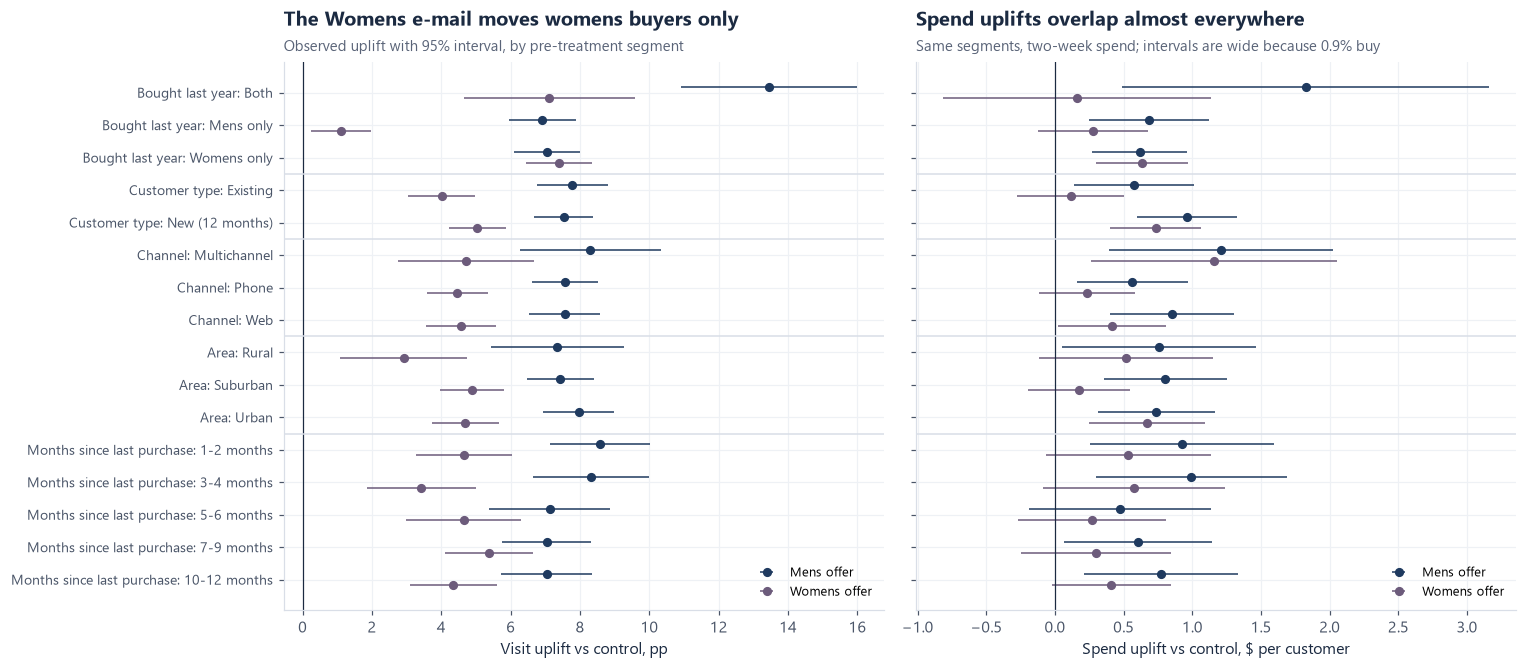

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True)
lab = [f"{a}: {b}" for a, b in zip(het["segmentation"], het["level"])]
yy = np.arange(len(het))
for ax, out, scale, unit in ((a1, "visit", 100, "Visit uplift vs control, pp"), (a2, "spend", 1, "Spend uplift vs control, $ per customer")):
    for t, short, off in (("Mens offer", "mens", -0.17), ("Womens offer", "womens", 0.17)):
        ax.errorbar(het[f"{short}_{out}"] * scale, yy + off, xerr=1.96 * het[f"{short}_{out}_se"] * scale, fmt="o", ms=5, color=COL[t],
                    ecolor=COL[t], elinewidth=1, capsize=0, label=t)
    ax.axvline(0, color=PALETTE["ink"], lw=0.8)
    for b in np.cumsum(het.groupby("segmentation", sort=False).size().values)[:-1]:
        ax.axhline(b - 0.5, color=PALETTE["light"], lw=1)
    ax.set_xlabel(unit)
    ax.legend(loc="lower right", fontsize=8.5)
a1.set_yticks(yy, lab, fontsize=9); a1.invert_yaxis()
headline(a1, "The Womens e-mail moves womens buyers only", "Observed uplift with 95% interval, by pre-treatment segment")
headline(a2, "Spend uplifts overlap almost everywhere", "Same segments, two-week spend; intervals are wide because 0.9% buy")
fig.tight_layout()
savefig(fig, "03-heterogeneity", FIG); plt.show()

Purchase history is the only segmentation where the gap between the two e-mails clearly varies (Cochran's Q = 75.6,
p < 0.001). The Mens e-mail lifts visits by about 7 points for mens-only and womens-only buyers alike, and by 13.4 points
for customers who bought both lines. The Womens e-mail lifts womens-only buyers by 7.4 points, the same as the Mens
e-mail does, and mens-only buyers by only 1.1. **The Womens e-mail is never clearly better than the Mens e-mail for any
group; at best it ties.** That is why a next-best-offer policy, which sends the Womens e-mail to 30% of customers,
cannot beat "Mens to everyone". Recency (p = 0.04 across five levels) would not survive a correction for testing five
segmentations (Bonferroni threshold 0.01). On spend, the intervals overlap almost everywhere.

## 7. Where targeting does pay: a limited contact budget

E-mail is nearly free, so with no contact limit the question is only which e-mail to send. With a limit (a quota of
sends, or a costlier channel such as direct mail), the ranking decides who gets contacted at all. This is the ETL's
targeting simulator: send the model's offer to the top *k*% by predicted uplift and nothing to the rest, against a
random *k*% sent the Mens offer. Bands are 90% bootstrap intervals (300 draws).

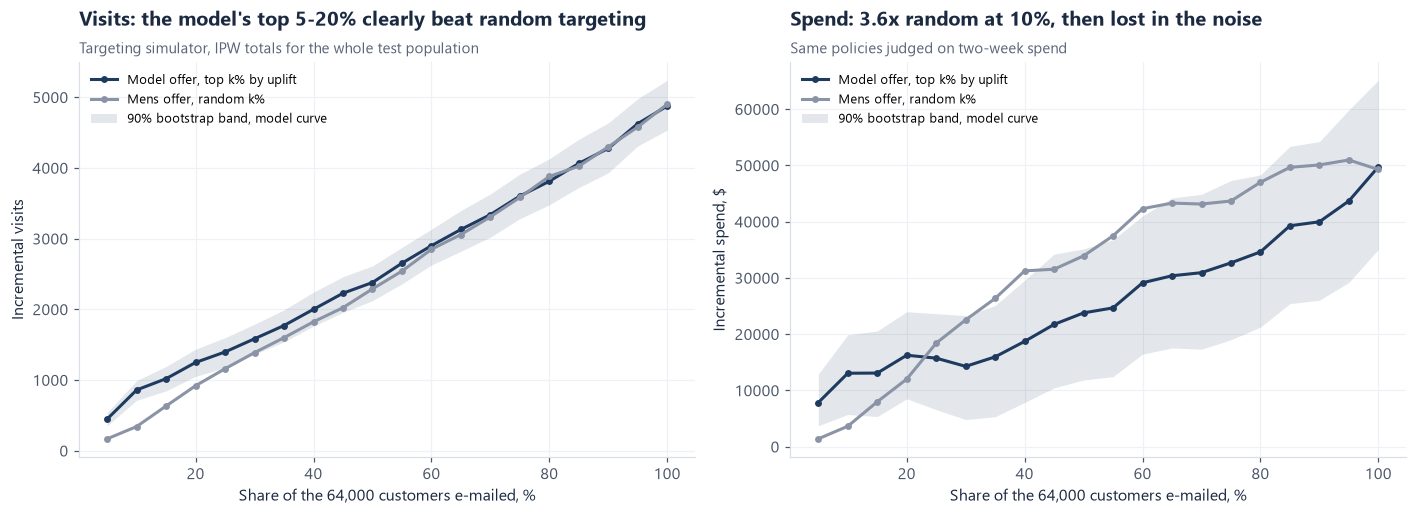

,"visits: Model offer, top k% by uplift","visits: Mens offer, random k%","spend: Model offer, top k% by uplift","spend: Mens offer, random k%","visits: model - random, 90% CI","spend: model - random, 90% CI"
target %,,,,,,
5,448.4818,168.1666,"7,841.9381","1,392.5546",142 to 395,"1,411 to 11,425"
10,859.6199,342.1473,"13,054.1366","3,636.5384",353 to 685,"1,762 to 15,881"
20,"1,248.5660",919.6607,"16,255.2821","12,019.3447",102 to 533,"-5,257 to 13,819"
30,"1,583.8718","1,387.9152","14,274.0438","22,537.4531",-37 to 453,"-19,511 to 1,997"
50,"2,379.4582","2,288.8743","23,781.1492","33,916.8987",-189 to 365,"-22,769 to 1,080"
100,"4,876.5528","4,901.7321","49,734.3442","49,268.9380",-244 to 169,"-8,121 to 9,073"


In [14]:
SH2 = np.round(np.arange(0.05, 1.0001, 0.05), 2)
rand_score = -np.argsort(np.random.default_rng(SEED).permutation(N)).astype(float)   # the ETL's random order: first k of a permutation
mens_all = np.array(["Mens offer"] * N)
tc = {}
for out, y in (("visits", visit), ("spend", spend)):
    tc[out] = {"Model offer, top k% by uplift": F.targeting_curve(h["BestUplift"], h["ModelOffer"], arm, y, SH2),
               "Mens offer, random k%": F.targeting_curve(rand_score, mens_all, arm, y, SH2)}
assert np.allclose(tc["spend"]["Mens offer, random k%"], pub_curve["RandomIncRevenue"].values[1:], rtol=0, atol=0.5)
assert np.allclose(tc["visits"]["Model offer, top k% by uplift"], pub_curve["ModelIncVisits"].values[1:], atol=0.05)
r = np.random.default_rng(SEED)
bands, diffs = {o: [] for o in tc}, {o: [] for o in tc}
for _ in range(300):
    ix = r.integers(0, N, N)
    for out, y in (("visits", visit), ("spend", spend)):
        mc = F.targeting_curve(h["BestUplift"].values[ix], h["ModelOffer"].values[ix], arm[ix], y[ix], SH2)
        bands[out].append(mc)
        diffs[out].append(mc - F.targeting_curve(rand_score[ix], mens_all, arm[ix], y[ix], SH2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, out, unit in zip(axes, ("visits", "spend"), ("Incremental visits", "Incremental spend, $")):
    for (k, v), c in zip(tc[out].items(), (PALETTE["navy"], PALETTE["grey"])):
        ax.plot(SH2 * 100, v, marker="o", ms=3.5, color=c, label=k)
    lo, hi = np.percentile(np.array(bands[out]), [5, 95], axis=0)
    ax.fill_between(SH2 * 100, lo, hi, color=PALETTE["navy"], alpha=0.12, lw=0, label="90% bootstrap band, model curve")
    ax.set_xlabel("Share of the 64,000 customers e-mailed, %"); ax.set_ylabel(unit); ax.legend(loc="upper left", fontsize=8.5)
v10 = tc["spend"]["Model offer, top k% by uplift"][1] / tc["spend"]["Mens offer, random k%"][1]
headline(axes[0], "Visits: the model's top 5-20% clearly beat random targeting", "Targeting simulator, IPW totals for the whole test population")
headline(axes[1], f"Spend: {v10:.1f}x random at 10%, then lost in the noise", "Same policies judged on two-week spend")
fig.tight_layout()
plt.show()
tgt = pd.DataFrame({f"{o}: {k}": v for o in tc for k, v in tc[o].items()}, index=pd.Index((SH2 * 100).astype(int), name="target %"))
for o in tc:
    lo, hi = np.percentile(np.array(diffs[o]), [5, 95], axis=0)
    tgt[f"{o}: model - random, 90% CI"] = [f"{a:,.0f} to {b:,.0f}" for a, b in zip(lo, hi)]
tgt.iloc[[0, 1, 3, 5, 9, 19]]

On visits, the model beats a random list of the same size at 5-20% of the base (the 90% interval of the difference
excludes zero). The lead fades by 30% and disappears by 50%. On spend, the model is 3.6x random at 10% ($13.1K vs $3.6K,
difference interval $1.8K-$15.9K) and cannot be told apart from random beyond 20%. At 30% the model curve even falls
below random, which is the noise of 578 buyers. The published "top 10% returns 3.6x" is right, and it is the only part
of the spend curve that is.

## 8. Designing the next test

The evidence says: deploy "Mens to everyone", keep a hold-out, and test the personalised policy prospectively before
trusting it. How big would that test have to be? Minimum detectable effect (two-sided 5%, 80% power, equal arms) for
the two outcomes, against the edge the personalised policy showed here.

In [15]:
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
p_mens = visit[arm == "Mens offer"].mean()
sd_spend = spend[arm == "Mens offer"].std()
n_grid = np.array([5_000, 10_000, 21_000, 50_000, 100_000, 250_000, 500_000, 1_000_000])
mde = pd.DataFrame({"customers_per_arm": n_grid, "mde_visit_pp": z * np.sqrt(2 * p_mens * (1 - p_mens) / n_grid) * 100,
                    "mde_spend_per_customer": z * sd_spend * np.sqrt(2 / n_grid)}).set_index("customers_per_arm")
edge_v = pairs.loc[("Model (production) vs All Mens", "visits per 1,000"), "difference"] / 1000
edge_s = pairs.loc[("Model (production) vs All Mens", "spend $ per 1,000"), "difference"] / 1000
need = {"visit": (z / edge_v) ** 2 * 2 * p_mens * (1 - p_mens) if edge_v > 0 else np.inf, "spend": (z * sd_spend / edge_s) ** 2 * 2 if edge_s > 0 else np.inf}
print(f"Observed edge of the personalised policy over Mens-to-all: {edge_v * 100:+.2f} pp visits, ${edge_s:+.4f} spend per customer")
print(f"Customers per arm to detect that edge with 80% power: visits {need['visit']:,.0f}; spend {need['spend']:,.0f}")
mde

Observed edge of the personalised policy over Mens-to-all: -0.04 pp visits, $+0.0073 spend per customer
Customers per arm to detect that edge with 80% power: visits inf; spend 93,565,422


,mde_visit_pp,mde_spend_per_customer
customers_per_arm,,
5000,2.1654,0.9948
10000,1.5312,0.7034
21000,1.0566,0.4854
50000,0.6848,0.3146
100000,0.4842,0.2224
250000,0.3062,0.1407
500000,0.2165,0.0995
1000000,0.1531,0.0703


With Hillstrom-sized arms (21,300), the smallest detectable difference is 1.06 points on visits and $0.49 per customer on
spend. The personalised policy's edge is -0.04 points and $0.007: detecting $0.007 would take about 94 million customers
per arm, and on visits there is no gain to detect.

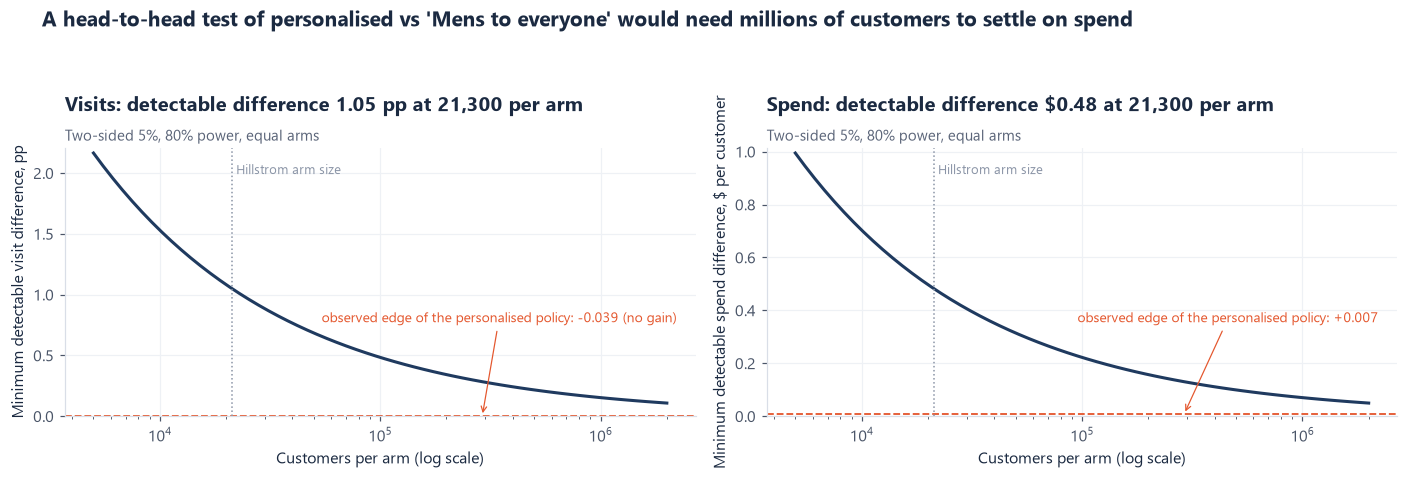

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
ng = np.logspace(np.log10(5_000), np.log10(2_000_000), 60)
for ax, ys, edge, unit, ttl in ((a1, z * np.sqrt(2 * p_mens * (1 - p_mens) / ng) * 100, edge_v * 100, "Minimum detectable visit difference, pp", "Visits"),
                                (a2, z * sd_spend * np.sqrt(2 / ng), edge_s, "Minimum detectable spend difference, $ per customer", "Spend")):
    ax.plot(ng, ys, color=PALETTE["navy"])
    ax.axhline(max(edge, 0), color=PALETTE["coral"], ls="--", lw=1.2)
    ax.annotate(f"observed edge of the personalised policy: {edge:+.3f}" + (" (no gain)" if edge <= 0 else ""), xy=(ng[40], max(edge, 0)),
                xytext=(0.97, 0.35), textcoords="axes fraction", ha="right", color=PALETTE["coral"], fontsize=9,
                arrowprops=dict(arrowstyle="->", color=PALETTE["coral"], lw=0.8))
    ax.axvline(21_300, color=PALETTE["grey"], ls=":", lw=1)
    ax.text(21_300, ys.max() * 0.92, " Hillstrom arm size", fontsize=8.5, color=PALETTE["grey"])
    ax.set_xscale("log"); ax.set_xlabel("Customers per arm (log scale)"); ax.set_ylabel(unit); ax.set_ylim(0, ys.max() * 1.02)
    mde_here = z * (np.sqrt(2 * p_mens * (1 - p_mens) / 21_300) * 100 if ttl == "Visits" else sd_spend * np.sqrt(2 / 21_300))
    headline(ax, f"{ttl}: detectable difference {mde_here:.2f} pp at 21,300 per arm" if ttl == "Visits" else f"{ttl}: detectable difference ${mde_here:.2f} at 21,300 per arm",
             "Two-sided 5%, 80% power, equal arms")
fig.suptitle("A head-to-head test of personalised vs 'Mens to everyone' would need millions of customers to settle on spend",
             x=0.04, ha="left", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

## 9. Recommendation

1. **Send everyone the Mens e-mail.** It is worth $770 per 1,000 customers per two-week campaign (95% CI $488-$1,024),
   about $16K across the 21,000 customers it reached in the test. There is no model to maintain and nothing to monitor
   beyond the campaign result.
2. **Keep a permanent random hold-out** (10% get no e-mail). The effect keeps being measured, decay and creative fatigue
   show up, and every future campaign is a free experiment.
3. **Use the uplift ranking only when contacts are limited.** If only 10% of the base can be reached (direct mail, a
   send quota), the model's top 10% returns 3.6x the spend of a random 10% ($13.1K vs $3.6K; 90% CI of the
   difference $1.8K-$15.9K).
4. **Do not test personalised vs "Mens to everyone".** At Hillstrom's 21,300 customers per arm, the minimum detectable
   difference is $0.49 per customer on spend and 1.06 points on visits. The observed edge is $0.007 and -0.04 points.
   Even the LightGBM policy's +$0.11 per customer would need about 400,000 customers per arm.
5. **Test what could move the number instead.** The next experiment should change the creative for the group the
   Womens e-mail reaches (womens-only buyers, 45% of the base), measured on visits, where 21,000 per arm detects a
   1-point change.

**Limitations.** The outcome window is two weeks, so long-term effects (repeat purchase, unsubscribes) are not
observed. Policy values are in-sample for the purchase-history rule, which picks the best e-mail per segment on the same
data that values it; the bias is small with three segments, and the model policy is cross-fitted. The test is from 2008,
so the effect sizes are illustrative of the method, not of a current e-mail programme.

In [17]:
report.update_metrics(METRICS, "03_uplift_and_policy", {
    "parity": {k: {"published": float(v["published"]), "reproduced": float(v["reproduced"])} for k, v in parity.iterrows()},
    "why_visit_z": {f"{t}|{o}": float(r_["z"]) for (t, o), r_ in why_own.iterrows()},
    "learners_auuc": {f"{t}|{k}": {"auuc": float(r_["auuc"]), "ci": [float(r_["ci_low"]), float(r_["ci_high"])], "capture_top30": float(r_["capture_top30"])}
                      for (t, k), r_ in learners.iterrows()},
    "uplift_calibration_slope": {t: float(v[0]) for t, v in fit.items()},
    "policies_inc_per_1000": {k: {"value": float(v["inc_per_1000"]), "ci": [float(v["ci_low_per_1000"]), float(v["ci_high_per_1000"])]} for k, v in pol.iterrows()},
    "model_vs_all_mens": {f"{c}|{o}": {"diff": float(v["difference"]), "ci": [float(v["ci_low"]), float(v["ci_high"])]} for (c, o), v in pairs.iterrows()},
    "heterogeneity_q": {k: {"Q": float(v["Q"]), "p": float(v["p_value"])} for k, v in qtest.iterrows()},
    "mde_at_21300_per_arm": {"visit_pp": float(z * np.sqrt(2 * p_mens * (1 - p_mens) / 21_300) * 100), "spend": float(z * sd_spend * np.sqrt(2 / 21_300))},
    "customers_per_arm_to_detect_edge": {k: float(v) for k, v in need.items()},
})
print(f"metrics written; notebook runtime {time.perf_counter() - T0:.0f}s")

metrics written; notebook runtime 209s
